<h1>Business Statistics Project</h1>
<b>Group 13:</b> Jurre Kamp, Resia Kilic, Thomas Boogaard, Zein Abou El Kheir 

<h2>1. Introduction</h2>

<h3>1.1 Background</h3>

<h3>1.2 Main Research Question and Sub-Questions</h3>

<b>To what extent are demographic characteristics significantly associated with users' perceived fairness of social media algorithms?</b>

This project investigates four demographic characteristics relation to the fairness:
<ol>
<li>Are there statistically significant differences in perceived fairness of social media algorithms across different educational levels?</li>
<li>What is the statistical relationship between users' country of origin and their perceived fairness of social media algorithms?</li>
<li>To what extent is the number of languages spoken significantly correlated with users' perceived fairness of social media algorithms?</li>
<li>How does perceived fairness of social media algorithms differ significantly between gender groups?</li>
</ol>

<h2>2. Dataset Description</h2>

<h2>3. Data Cleaning and Exploration</h2>

In [1]:
# Importing the libraries needed
import pandas as pd


In [2]:
# Reading the dataset
df_original = pd.read_excel("Responses.xlsx")

# We create a copy of the original df to work on it
df = df_original.copy()

df_original.head()

,ID,Start time,Completion time,Email,Name,Last modified time,Please share your email address,In which country are you located?,What is your country of origin?,Which description fits your parents' country of origin the best?,...,I scroll through recommendations,I end up watching videos I didn't intend to watch,Scrolling feels like a habit rather than a conscious choice,I sometimes spend more time scrolling than I had planned,"I feel like my feed shows me a good mix of topics to stay informed (e.g., news, social issues, or different opinons)",I believe that the algorithm hides certain social or political views,I feel like I have a fair chance to be seen/heard,I trust the algorithm to recommend me content fairly,What matters most to you? (1 being the most important and the last number being the least important),I think social media is fair2
0,1,2025-11-04 16:03:57,2025-11-04 16:09:58,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Sometimes,Agree,Agree,Agree,Agree,Neutral,Neutral,Democratic values (respect for other views and...,Agree
1,2,2025-11-04 18:56:25,2025-11-04 19:00:13,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Rarely,Strongly agree,Strongly agree,Neutral,Strongly agree,Agree,Neutral,Equity (opportunities based upon your needs);A...,Neutral
2,3,2025-11-04 22:44:10,2025-11-04 22:51:50,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Sometimes,Sometimes,Strongly agree,Strongly agree,Strongly disagree,Strongly agree,Disagree,Strongly disagree,Equity (opportunities based upon your needs);A...,Strongly disagree
3,4,2025-11-05 07:47:43,2025-11-05 07:57:56,anonymous,NaN,NaN,NaN,Malta,Spain,Both parents are born and brought up in the Spain,...,Rarely,Sometimes,Disagree,Agree,Agree,Agree,Neutral,Neutral,Autonomy (ability to decide for myself);Democr...,Disagree
4,5,2025-11-05 09:03:17,2025-11-05 09:11:07,anonymous,NaN,NaN,NaN,The Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Sometimes,Disagree,Agree,Disagree,Agree,Disagree,Strongly disagree,Equity (opportunities based upon your needs);D...,Strongly disagree


<h3>3.1 Dictionary for Responses</h3>

<h3>3.2 Dictionary for Survey Questions

In [3]:
# Mapping th original Excel column names to research paper abbreviations

column_dictionary = {

    # Administrative and identification variables
    "ID": "respondent_id",
    "Start time": "start_time",
    "Completion time": "completion_time",
    "Email": "email",
    "Name": "name",
    "Last modified time": "last_modified_time",
    "Please share your email address": "email_address",

    # Demographic variables
    "In which country are you located?": "current_country",
    "What is your country of origin?": "Moderator1",
    "Which description fits your parents' country of origin the best?": "Moderator3",
    "What's your highest/current level of education?": "education_level",
    "How many languages do you speak?": "languages_spoken",
    "Which languages do you use most online? (select all that applies)": "online_languages",
    "What age group are you in?": "age_group",
    "What is your gender?": "Moderator2",

    # General social media and perceived fairness
    "I use social media": "social_media_use",
    "I think social media is fair": "PF2_before",

    # Uniform Content Distribution (UCD)
    "I see repeated topics on my feed": "UCD1",
    "I see different opinions on the same topic": "UCD2",
    "My feed varies within my social circle\xa0": "UCD3",

    # Universally Accessible Environment (UAE)
    "I often notice that someone didn't know about a trend, which I thought everybody had seen\xa0": "UAE1",
    "It is harder for me to take part in a discussion regarding a topic when I have not seen the topic on my feed yet\xa0": "UAE2",
    "I notice that people mostly agree with what's trending, they rarely add their own personal views - add happens to options": "UAE3",
    "A topic/trend usually stays on my feed for ...": "UAE4",

    
    # Reinforced Existing Views and Preferences (REVP)
    "When I see a post and open the comments, the top comments reflect what I am already thinking about": "REVP1",
    "I scroll through the comments to see if someone has mentioned what I am thinking about": "REVP2",
    "I notice a lot of agreement with the content in the comments": "REVP3",
    "I tend to comment on content I disagree with": "REVP4",
    "I often see new ideas and topics on my feed\xa0": "REVP5",
    "When I see a new topic on my feed, I tend to scroll away": "REVP6",

    # Biased Content (BC)
    "My feed does not show information that others could be seeing": "BC1",
    "I feel like my content gets the same number of views as content from others": "BC2",
    "I feel like my content gets the same number of views as content from others with a different background  (e.g., race, gender, age)\xa0than mine": "BC3",
    "I think content from certain groups of people is prioritized over other groups\xa0": "BC4",
    "I am informed that my feed is shaped by personal information like my age, gender or location - transparency\xa0": "BC5",

    # Normative Counterfactual Reasoning (NCR)
    "I would feel comfortable swapping feeds with someone from a different background than mine (e.g., age, race, beliefs)": "NCR1",
    "If everyone got my feed, I think some people might be shocked by the content they see": "NCR2",
    "I would be okay seeing less of my favorite type of content if it meant more equal exposure for everyone": "NCR3",
    "If I had to exchange feeds with someone really different from me, I don't think I would like what I would see": "NCR4",

    # Democratic Values and Power (DVP)
    "When I post about topics like politics or social issues, it feels like my voice can be seen and heard": "DVP1",
    "I have seen political content that felt one-sided or biased": "DVP2",
    "I feel like the algorithm shapes what political topics I get to see": "DVP3",
    "I rarely see posts that challenge my own political views unless I search for them": "DVP4",
    "I've seen creators mention that their political-related content was shadowbanned\xa0": "DVP5",


    # Rational and Autonomous Decision-Making (RAD)
    "I feel I am in control of my feed": "RAD1",
    "I can influence the type of content I get on my feed": "RAD2",
    "The algorithm decides what I watch": "RAD3",
    "I scroll through recommendations": "RAD4",
    "I end up watching videos I didn't intend to watch": "RAD5",
    "Scrolling feels like a habit rather than a conscious choice": "RAD6",
    "I sometimes spend more time scrolling than I had planned": "RAD7",

    # Opportunity and Need (ON)
    "I feel like my feed shows me a good mix of topics to stay informed (e.g., news, social issues, or different opinons)": "ON1",
    "I believe that the algorithm hides certain social or political views": "ON2",
    "I feel like I have a fair chance to be seen/heard": "ON3",

    # Perceived Fairness (PF)
    "I trust the algorithm to recommend me content fairly": "PF1",
    "I think social media is fair2": "PF2_after",

    # Additional ranking question
    "What matters most to you? (1 being the most important and the last number being the least important)": "justice_values_ranking"
}


# Renaming all the df columns using the dictionary
df = df.rename(columns=column_dictionary)

# Display the renamed df
display(df.head())
df.columns.to_list()

,respondent_id,start_time,completion_time,email,name,last_modified_time,email_address,current_country,Moderator1,Moderator3,...,RAD4,RAD5,RAD6,RAD7,ON1,ON2,ON3,PF1,justice_values_ranking,PF2_after
0,1,2025-11-04 16:03:57,2025-11-04 16:09:58,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Sometimes,Agree,Agree,Agree,Agree,Neutral,Neutral,Democratic values (respect for other views and...,Agree
1,2,2025-11-04 18:56:25,2025-11-04 19:00:13,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Rarely,Strongly agree,Strongly agree,Neutral,Strongly agree,Agree,Neutral,Equity (opportunities based upon your needs);A...,Neutral
2,3,2025-11-04 22:44:10,2025-11-04 22:51:50,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Sometimes,Sometimes,Strongly agree,Strongly agree,Strongly disagree,Strongly agree,Disagree,Strongly disagree,Equity (opportunities based upon your needs);A...,Strongly disagree
3,4,2025-11-05 07:47:43,2025-11-05 07:57:56,anonymous,NaN,NaN,NaN,Malta,Spain,Both parents are born and brought up in the Spain,...,Rarely,Sometimes,Disagree,Agree,Agree,Agree,Neutral,Neutral,Autonomy (ability to decide for myself);Democr...,Disagree
4,5,2025-11-05 09:03:17,2025-11-05 09:11:07,anonymous,NaN,NaN,NaN,The Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Sometimes,Disagree,Agree,Disagree,Agree,Disagree,Strongly disagree,Equity (opportunities based upon your needs);D...,Strongly disagree


['respondent_id',
 'start_time',
 'completion_time',
 'email',
 'name',
 'last_modified_time',
 'email_address',
 'current_country',
 'Moderator1',
 'Moderator3',
 'education_level',
 'languages_spoken',
 'online_languages',
 'age_group',
 'Moderator2',
 'social_media_use',
 'PF2_before',
 'UCD1',
 'UCD2',
 'UCD3',
 'UAE1',
 'UAE2',
 'UAE3',
 'UAE4',
 'REVP1',
 'REVP2',
 'REVP3',
 'REVP4',
 'REVP5',
 'REVP6',
 'BC1',
 'BC2',
 'BC3',
 'BC4',
 'BC5',
 'NCR1',
 'NCR2',
 'NCR3',
 'NCR4',
 'DVP1',
 'DVP2',
 'DVP3',
 'DVP4',
 'DVP5',
 'RAD1',
 'RAD2',
 'RAD3',
 'RAD4',
 'RAD5',
 'RAD6',
 'RAD7',
 'ON1',
 'ON2',
 'ON3',
 'PF1',
 'justice_values_ranking',
 'PF2_after']

<h2>4. Are there statistically significant differences in perceived fairness of social media algorithms across different educational levels?</h2>

<h2>5. What is the statistical relationship between users' country of origin and their perceived fairness of social media algorithms?</h2>

<h3>5.1 Hypotheses</h3>

- **H0:** Mean perceived fairness is equal across countries of origin.
- **H1:** Mean perceived fairness differs between at least two countries of origin.

Significance level: α = 0.05.

In [4]:
# Author: Zein
import pandas as pd                     # tables (DataFrames): read Excel, filter, group (5.2-5.3)
import numpy as np                      # number functions and NaN (empty value)
import matplotlib.pyplot as plt         # charts: boxplot (5.4)
from scipy import stats                 # tests: Levene, Shapiro (5.5), ANOVA, Kruskal (5.6), t-test (5.8), chi2 (5.9)
from statsmodels.stats.multicomp import pairwise_tukeyhsd   # Tukey HSD post-hoc test (5.7)
import semopy                           # structural equation modelling (5.10)

df_origin = pd.read_excel("Responses.xlsx")   # load the raw survey; answers are still text, not 1-5

<h3>5.2 Data preparation</h3>

Only the columns needed for this sub-question are kept and renamed with the abbreviations from the column dictionary (section 3.2).

In [5]:
# Author: Zein
cols = {                                                                     # the 6 columns we need: long Excel name -> short code (section 3.2)
    "What is your country of origin?": "Moderator1",                         # groups: country of origin
    "I trust the algorithm to recommend me content fairly": "PF1",           # perceived fairness item 1
    "I think social media is fair": "PF2_before",                            # perceived fairness item 2 (start of survey)
    "I think social media is fair2": "PF2_after",                            # same question again (end of survey)
    "I feel I am in control of my feed": "RAD1",                             # autonomy item 1 (for the SEM)
    "I can influence the type of content I get on my feed": "RAD2",          # autonomy item 2 (for the SEM)
}
df_origin = df_origin[list(cols)].rename(columns=cols)                       # keep only these 6 columns and rename them

# Likert answers -> numbers 1-5
likert = {"Strongly disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strongly agree": 5}   # text -> number
for c in ["PF1", "PF2_before", "PF2_after", "RAD1", "RAD2"]:                 # repeat for each Likert column (not country)
    df_origin[c] = df_origin[c].astype(str).str.strip().map(likert)          # to text, cut spaces, look up number; no match -> NaN

df_origin.head()                                                             # show the first 5 rows as a check

,Moderator1,PF1,PF2_before,PF2_after,RAD1,RAD2
0,Spain,3.0,2.0,4.0,4.0,4.0
1,Spain,3.0,3.0,3.0,3.0,3.0
2,Spain,1.0,3.0,1.0,2.0,3.0
3,Spain,3.0,2.0,2.0,3.0,4.0
4,Spain,1.0,3.0,1.0,4.0,5.0


**Cleaning country of origin.** The answers were typed freely, so the same country appears in different spellings and languages (e.g. "Nederland", "Holland", "NL"). Variants are merged, and countries are grouped into the four survey countries plus "Outside EU". Answers naming two countries, and answers that are not a country, are set to missing.

In [6]:
# Author: Zein
# the 27 EU member states, used to sort countries into "Other EU" or "Outside EU"
EU = ["Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia", "Denmark", "Estonia", "Finland",
      "France", "Germany", "Greece", "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg",
      "Malta", "Netherlands", "Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden"]

# spelling variants, typos, other languages and cities (EU and non-EU) -> one official country name
aliases = {
    "nederland": "Netherlands", "the netherlands": "Netherlands", "netherland": "Netherlands",
    "holland": "Netherlands", "nl": "Netherlands", "amsterdam": "Netherlands", "dutch": "Netherlands",
    "nehterlands": "Netherlands", "nederlands": "Netherlands", "fryslan": "Netherlands",
    "netherlands, ethnically from lebanon": "Netherlands",
    "españa": "Spain", "deutschland": "Germany", "german": "Germany", "getmany": "Germany",
    "germsny": "Germany", "i was born in germany, but my family is originally from sri lanka.": "Germany",
    "greece.": "Greece", "greek": "Greece", "creta island in greece": "Greece",
    "england": "United Kingdom", "uk": "United Kingdom", "usa": "United States",
    "سورية": "Syria", "syrien": "Syria", "born in syria but originally im palestinian.": "Syria",
    "morrocco": "Morocco", "morroco": "Morocco", "marocco": "Morocco", "surinam": "Suriname",
    "suriname, molukken, irak": "Suriname", "kazahstan": "Kazakhstan", "irland": "Ireland",
    "bulgarian": "Bulgaria", "chinese": "China", "frankrijk": "France", "turkiye": "Turkey",
    "my parents are from pakistan": "Pakistan",
}
invalid = ["yes", "manerf", "nan", ""]                 # answers that are not a country

def clean_country(x):                                  # raw answer -> clean country name
    s = str(x).strip()                                 # to text, cut spaces at start/end
    key = s.lower()                                    # lowercase, so "HOLLAND" = "holland"
    if key in invalid or "/" in s or "&" in s:         # not a country, or two countries named
        return np.nan                                  # -> missing (assigning one would be a guess)
    return aliases.get(key, s.title())                 # in aliases -> official name; else capitalise ("france" -> "France")

def origin_group(country):                             # clean country name -> analysis group
    if pd.isna(country):                               # missing stays missing
        return np.nan
    if country in ["Netherlands", "Germany", "Spain", "Greece"]:   # the 4 survey countries are large enough
        return country                                 # -> own group
    return "Other EU" if country in EU else "Outside EU"           # rest: EU member or not

df_origin["origin_country"] = df_origin["Moderator1"].apply(clean_country)     # run clean_country on every row -> new column
df_origin["origin_group"] = df_origin["origin_country"].apply(origin_group)    # run origin_group on every row -> new column
df_origin["origin_group"].value_counts(dropna=False)                           # count people per group, including missing

origin_group
Germany        178
Netherlands    146
Spain          132
Outside EU     110
Greece          92
Other EU        16
NaN             11
Name: count, dtype: int64

"Other EU" is too small for a reliable group comparison, so it is excluded from the tests. This is reported as a limitation.

In [7]:
# Author: Zein
groups = ["Netherlands", "Germany", "Spain", "Greece", "Outside EU"]           # the 5 groups we test ("Other EU" left out, n = 16)
df_origin = df_origin[df_origin["origin_group"].isin(groups)].copy()            # keep only rows in these groups (drops Other EU + missing)
df_origin["origin_EU"] = np.where(df_origin["origin_group"] == "Outside EU", "Outside EU", "EU")   # IF Outside EU -> "Outside EU", else "EU" (for the t-test, 5.8)
print("Respondents kept:", len(df_origin))                                      # number of rows left

Respondents kept: 658


<h3>5.3 Perceived fairness score and reliability</h3>

Perceived fairness (PF) is the mean of PF1, PF2_before and PF2_after. Cronbach's alpha checks whether the three items measure the same construct (≥ 0.70 is acceptable).

In [8]:
# Author: Zein
pf_items = ["PF1", "PF2_before", "PF2_after"]          # the 3 perceived fairness items

def cronbach_alpha(items):                             # do the items measure the same thing?
    items = items.dropna()                             # only people who answered all items
    k = items.shape[1]                                 # number of items (columns) = 3
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))   # k/(k-1) * (1 - sum of item variances / variance of total score)

print("Cronbach's alpha PF:", round(cronbach_alpha(df_origin[pf_items]), 2))   # >= 0.70 = acceptable

df_origin["PF"] = df_origin[pf_items].mean(axis=1, skipna=False)   # PF score = mean of the 3 items per person; any item missing -> NaN
df_origin = df_origin.dropna(subset=["PF"])                        # drop people without a complete PF score
print("Respondents with a complete PF score:", len(df_origin))      # number of rows left

Cronbach's alpha PF: 0.71
Respondents with a complete PF score: 644


<h3>5.4 Exploratory data analysis</h3>

In [9]:
# Author: Zein
summary = (df_origin.groupby("origin_group")["PF"]                       # split PF scores by origin group
           .agg(n="count", mean="mean", median="median", sd="std",       # per group: size, mean, median, standard deviation,
                Q1=lambda x: x.quantile(0.25), Q3=lambda x: x.quantile(0.75))   # bottom (25%) and top (75%) of the boxplot box
           .reindex(groups).round(2))                                    # rows in our fixed group order, 2 decimals
summary                                                                  # show the table

,n,mean,median,sd,Q1,Q3
origin_group,,,,,,
Netherlands,144,2.93,3.00,0.76,2.33,3.33
Germany,173,2.61,2.67,0.70,2.00,3.00
Spain,128,2.89,3.00,0.72,2.33,3.33
Greece,90,2.79,2.83,0.65,2.33,3.00
Outside EU,109,2.57,2.67,0.70,2.00,3.00


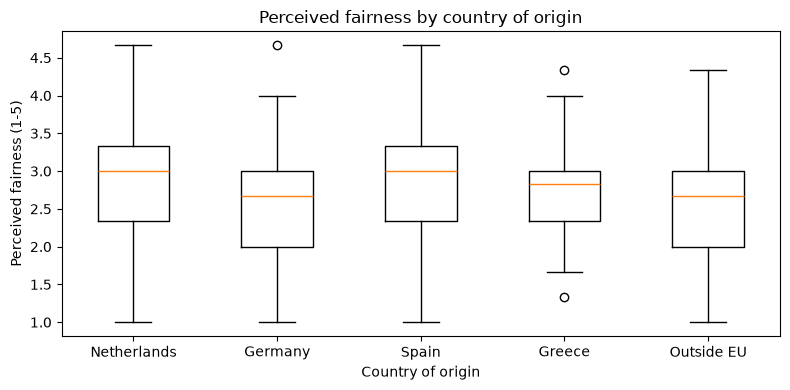

In [10]:
# Author: Zein
fig, ax = plt.subplots(figsize=(8, 4))                                   # empty chart, 8 x 4 inches
ax.boxplot([df_origin.loc[df_origin["origin_group"] == g, "PF"] for g in groups], tick_labels=groups)   # one box of PF scores per group
ax.set_title("Perceived fairness by country of origin")                  # chart title
ax.set_xlabel("Country of origin")                                       # x-axis label
ax.set_ylabel("Perceived fairness (1-5)")                                # y-axis label
plt.tight_layout()                                                       # fit labels inside the figure
plt.show()                                                               # draw the chart

<h3>5.5 Checking the ANOVA assumptions</h3>

1. **Independence:** each respondent answered once, so observations are independent.
2. **Equal variances:** Levene's test (H0: variances are equal).
3. **Normality:** Shapiro-Wilk on the residuals (H0: residuals are normal).

In [11]:
# Author: Zein
samples = [df_origin.loc[df_origin["origin_group"] == g, "PF"] for g in groups]   # 5 lists: the PF scores of each group

lev = stats.levene(*samples)                                             # Levene: are the group variances equal? (H0: yes)
print(f"Levene: W = {lev.statistic:.3f}, p = {lev.pvalue:.4f}")          # p > 0.05 -> keep H0 -> equal variances OK

residuals = df_origin["PF"] - df_origin.groupby("origin_group")["PF"].transform("mean")   # residual = own PF - mean of own group
sh = stats.shapiro(residuals)                                            # Shapiro-Wilk: are the residuals normal? (H0: yes)
print(f"Shapiro-Wilk on residuals: W = {sh.statistic:.3f}, p = {sh.pvalue:.4f}")   # p < 0.05 -> not normal -> also run Kruskal-Wallis (5.6)

Levene: W = 0.461, p = 0.7646
Shapiro-Wilk on residuals: W = 0.990, p = 0.0002


<h3>5.6 One-way ANOVA and Kruskal-Wallis</h3>

*(In progress, Zein)*

<h3>5.7 Post-hoc test: which groups differ?</h3>

*(In progress, Zein)*

<h3>5.8 EU vs. outside-EU origin (two-sample t-test)</h3>

*(In progress, Zein)*

<h3>5.9 Chi-square test of independence</h3>

*(In progress, Zein)*

<h3>5.10 Structural equation model per origin group</h3>

*(In progress, Zein)*

<h3>5.11 Findings and conclusion</h3>

*(In progress, Zein)*

<h2> 6. To what extent is the number of languages spoken significantly correlated with users' perceived fairness of social media algorithms?</h2>

<h2>7. How does perceived fairness of social media algorithms differ significantly between gender groups?</h2>

<h2>8. Overall Results </h2>

<h2>9. Conclusion</h2>

<h2>10. References</h2>

Diptish Dey, Mona Z. Alashhy, Debarati Bhaumik, and Jesse W. J. Weltevreden. 2026. A Methodology to Assess Polarization
on Social Media. In <i>The 2026 ACM Conference on Fairness, Accountability, and Transparency (FAccT ’26), June 25–28, 2026,
Montreal, QC, Canada.</i> ACM, New York, NY, USA, 21 pages. https://doi.org/10.1145/3805689.3812263
